In [52]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from config import Config

Сначала исследую тренировочные данные

In [2]:
df = pd.read_csv(Config.TRAIN_DIR)
df.columns

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='str')

In [3]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [4]:
df.duplicated().sum( )

np.int64(0)

In [5]:
df.PassengerId.count()

np.int64(891)

In [6]:
df['Age_Is_Null'] = df['Age'].isnull().astype(int)

print(df.groupby('Age_Is_Null')['Survived'].mean())

Age_Is_Null
0    0.406162
1    0.293785
Name: Survived, dtype: float64


У нас интересный инсайт, разница выживаемости в 11 процентов у людей у которых нет данных о возрасте, это можно оставить как новую фичу

In [7]:
# Создаем бинарный признак: 1, если каюта заполнена, 0 — если пропущена (NaN)
df['Has_Cabin'] = df['Cabin'].notnull().astype(int)

print(df.groupby('Has_Cabin')['Survived'].mean())

Has_Cabin
0    0.299854
1    0.666667
Name: Survived, dtype: float64


У нас опять инсайт, люди с каютой выживали гораздо чаще, но в самом признаке огромное кол-во пропусков, поэтому исходный признак лучше дропнуть

In [8]:
df.drop('Cabin', axis=1, inplace=True)

In [9]:
df.columns

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Embarked', 'Age_Is_Null', 'Has_Cabin'],
      dtype='str')

In [10]:
df['Sex']

0        male
1      female
2      female
3      female
4        male
        ...  
886      male
887    female
888    female
889      male
890      male
Name: Sex, Length: 891, dtype: str

In [11]:
# Превращаем в бинарный признак
df = pd.get_dummies(df, columns=['Sex'], drop_first=True)

In [12]:
df.columns

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Age', 'SibSp', 'Parch',
       'Ticket', 'Fare', 'Embarked', 'Age_Is_Null', 'Has_Cabin', 'Sex_male'],
      dtype='str')

In [13]:
df['Embarked'].value_counts(dropna=False)


Embarked
S      644
C      168
Q       77
NaN      2
Name: count, dtype: int64

In [14]:
# Превращаем в бинарный признак
df['Embarked'] = df['Embarked'].fillna('S')
df = pd.get_dummies(df, columns=['Embarked'], drop_first=True)

In [15]:
df

,PassengerId,Survived,Pclass,Name,Age,SibSp,Parch,Ticket,Fare,Age_Is_Null,Has_Cabin,Sex_male,Embarked_Q,Embarked_S
0,1,0,3,"Braund, Mr. Owen Harris",22.0,1,0,A/5 21171,7.2500,0,0,True,False,True
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",38.0,1,0,PC 17599,71.2833,0,1,False,False,False
2,3,1,3,"Heikkinen, Miss. Laina",26.0,0,0,STON/O2. 3101282,7.9250,0,0,False,False,True
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",35.0,1,0,113803,53.1000,0,1,False,False,True
4,5,0,3,"Allen, Mr. William Henry",35.0,0,0,373450,8.0500,0,0,True,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",27.0,0,0,211536,13.0000,0,0,True,False,True
887,888,1,1,"Graham, Miss. Margaret Edith",19.0,0,0,112053,30.0000,0,1,False,False,True
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",NaN,1,2,W./C. 6607,23.4500,1,0,False,False,True
889,890,1,1,"Behr, Mr. Karl Howell",26.0,0,0,111369,30.0000,0,1,True,False,False


In [16]:
df.columns

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Age', 'SibSp', 'Parch',
       'Ticket', 'Fare', 'Age_Is_Null', 'Has_Cabin', 'Sex_male', 'Embarked_Q',
       'Embarked_S'],
      dtype='str')

<Axes: >

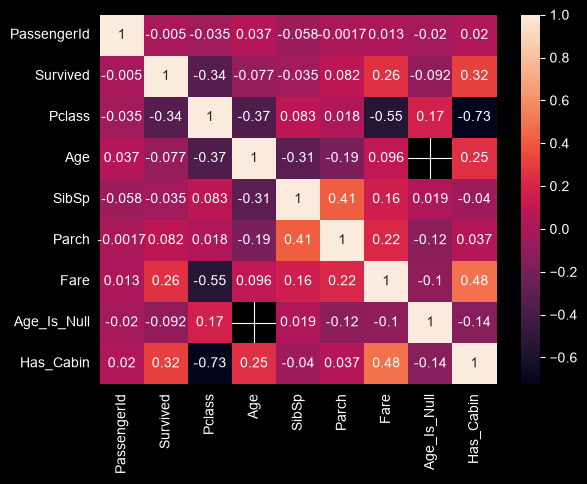

In [17]:
corr = df.select_dtypes(include=['number']).corr()

sns.heatmap(corr, annot=True)

Наибольшая корреляция у пропущенного возраста с классом, соответсвенно можно заполнить пропуски медианой по классу

In [19]:
df['FamilySize'] = df['SibSp'] + df['Parch'] + 1
df['IsAlone'] = (df['FamilySize'] == 1).astype(int)

<Axes: >

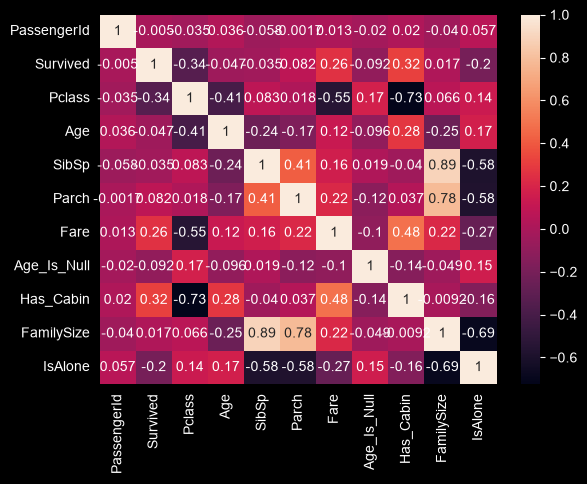

In [20]:
corr = df.select_dtypes(include=['number']).corr()

sns.heatmap(corr, annot=True)

In [21]:
df.drop('Ticket', axis=1, inplace=True)


C:\Users\wany0\AppData\Local\Temp\ipykernel_21620\1862354190.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = df.select_dtypes(


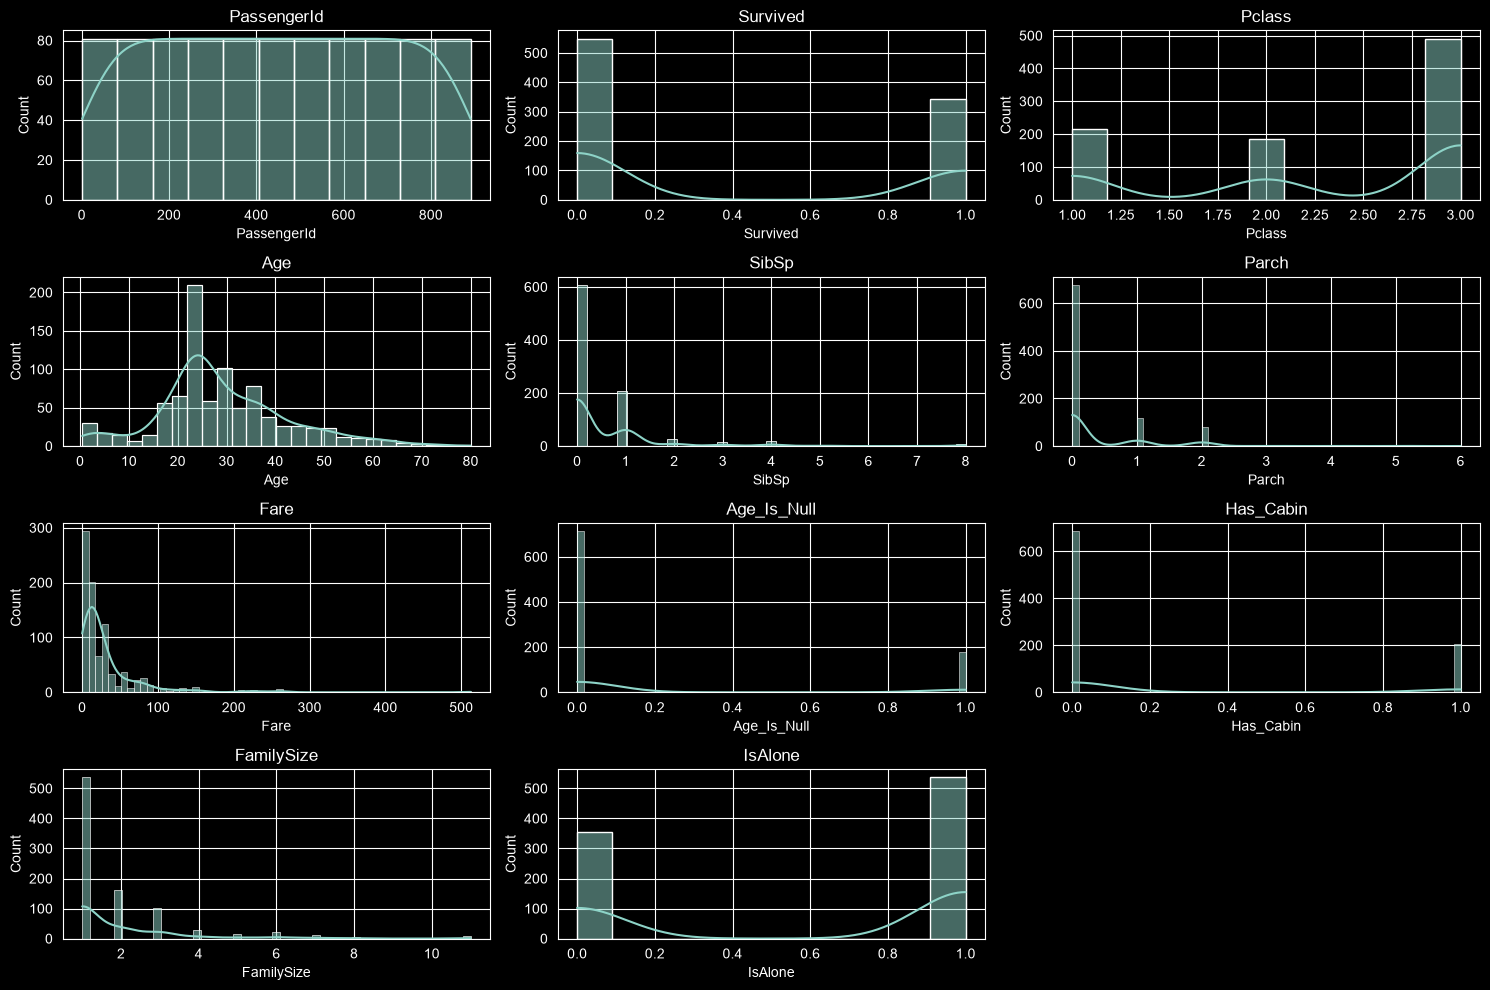

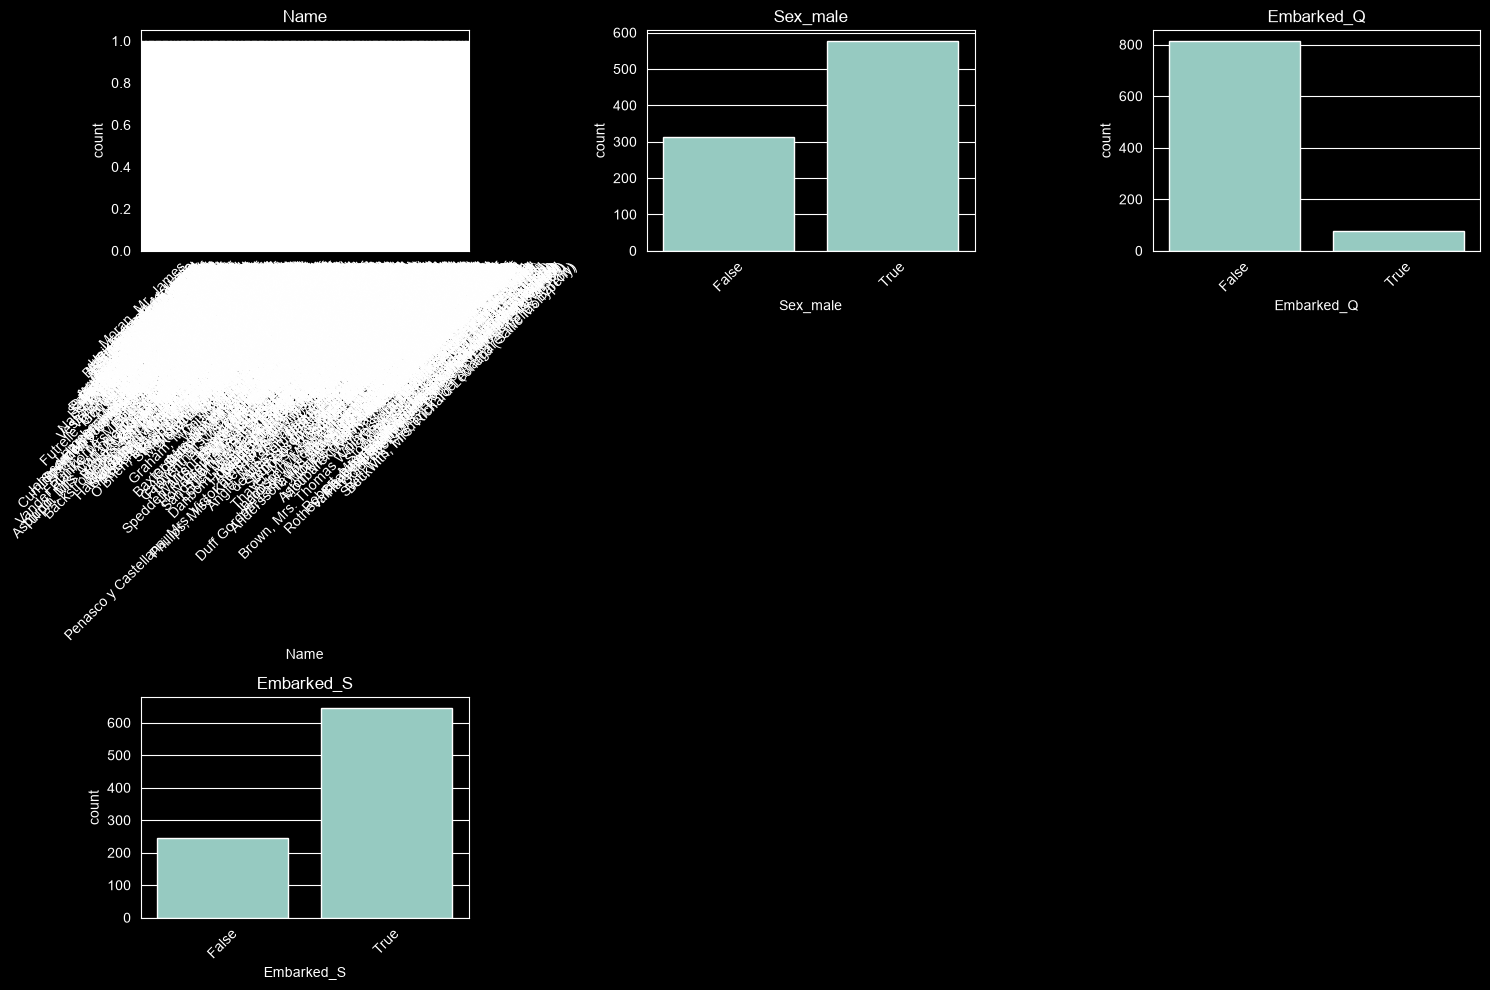

In [22]:
numerical_features = df.select_dtypes(include=['int64', 'float64']).columns
categorical_features = df.select_dtypes(
    include=['object', 'category', 'bool']
).columns

plt.figure(figsize=(15, 10))
for i, col in enumerate(numerical_features):
  plt.subplot((len(numerical_features) // 3) + 1, 3, i + 1)
  sns.histplot(df[col], kde=True)
  plt.title(col)
plt.tight_layout()
plt.show()

plt.figure(figsize=(15, 10))
for i, col in enumerate(categorical_features):
  plt.subplot((len(categorical_features) // 3) + 1, 3, i + 1)
  sns.countplot(data=df, x=col)
  plt.title(col)
  plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [23]:
df['Fare'] = np.log1p(df['Fare'])

<Axes: xlabel='SibSp', ylabel='count'>

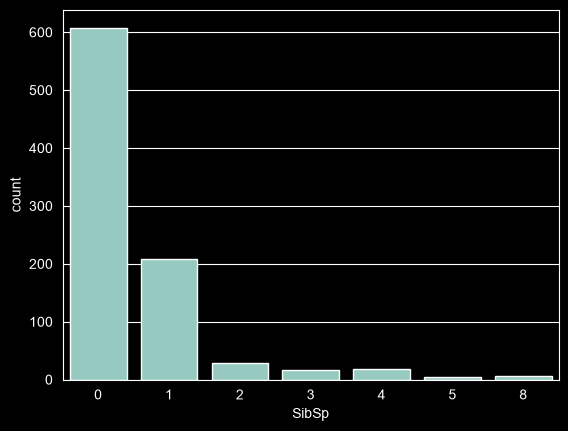

In [24]:
sns.countplot(data=df, x='SibSp')

<Axes: xlabel='Parch', ylabel='count'>

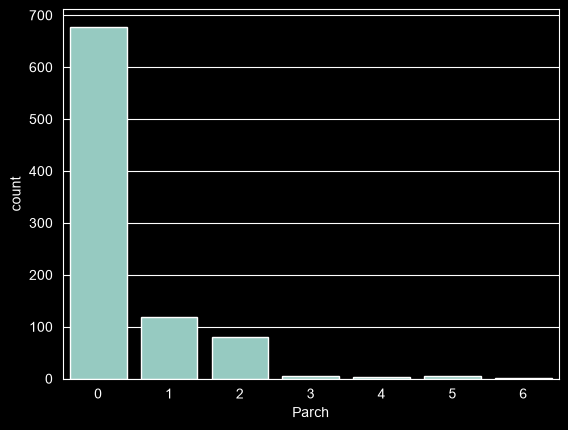

In [25]:
sns.countplot(data=df, x='Parch')


In [26]:
df.isnull().sum()

PassengerId    0
Survived       0
Pclass         0
Name           0
Age            0
SibSp          0
Parch          0
Fare           0
Age_Is_Null    0
Has_Cabin      0
Sex_male       0
Embarked_Q     0
Embarked_S     0
FamilySize     0
IsAlone        0
dtype: int64

In [27]:
df.columns

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Age', 'SibSp', 'Parch',
       'Fare', 'Age_Is_Null', 'Has_Cabin', 'Sex_male', 'Embarked_Q',
       'Embarked_S', 'FamilySize', 'IsAlone'],
      dtype='str')

In [28]:
df['Name'].count()


np.int64(891)

In [29]:
df.columns

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Age', 'SibSp', 'Parch',
       'Fare', 'Age_Is_Null', 'Has_Cabin', 'Sex_male', 'Embarked_Q',
       'Embarked_S', 'FamilySize', 'IsAlone'],
      dtype='str')

In [30]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare,Age_Is_Null,Has_Cabin,FamilySize,IsAlone
count,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.066409,0.523008,0.381594,2.962246,0.198653,0.228956,1.904602,0.602694
std,257.353842,0.486592,0.836071,13.244532,1.102743,0.806057,0.969048,0.399210,0.420397,1.613459,0.489615
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000
25%,223.500000,0.000000,2.000000,22.000000,0.000000,0.000000,2.187218,0.000000,0.000000,1.000000,0.000000
50%,446.000000,0.000000,3.000000,26.000000,0.000000,0.000000,2.737881,0.000000,0.000000,1.000000,1.000000
75%,668.500000,1.000000,3.000000,37.000000,1.000000,0.000000,3.465736,0.000000,0.000000,2.000000,1.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,6.240917,1.000000,1.000000,11.000000,1.000000


In [31]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Age          891 non-null    float64
 5   SibSp        891 non-null    int64  
 6   Parch        891 non-null    int64  
 7   Fare         891 non-null    float64
 8   Age_Is_Null  891 non-null    int64  
 9   Has_Cabin    891 non-null    int64  
 10  Sex_male     891 non-null    bool   
 11  Embarked_Q   891 non-null    bool   
 12  Embarked_S   891 non-null    bool   
 13  FamilySize   891 non-null    int64  
 14  IsAlone      891 non-null    int64  
dtypes: bool(3), float64(2), int64(9), str(1)
memory usage: 86.3 KB


In [32]:
df.head()

,PassengerId,Survived,Pclass,Name,Age,SibSp,Parch,Fare,Age_Is_Null,Has_Cabin,Sex_male,Embarked_Q,Embarked_S,FamilySize,IsAlone
0,1,0,3,"Braund, Mr. Owen Harris",22.0,1,0,2.110213,0,0,True,False,True,2,0
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",38.0,1,0,4.280593,0,1,False,False,False,2,0
2,3,1,3,"Heikkinen, Miss. Laina",26.0,0,0,2.188856,0,0,False,False,True,1,1
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",35.0,1,0,3.990834,0,1,False,False,True,2,0
4,5,0,3,"Allen, Mr. William Henry",35.0,0,0,2.202765,0,0,True,False,True,1,1


In [33]:
from pandas.api.types import CategoricalDtype

pclass_type = CategoricalDtype(categories=[1, 2, 3], ordered=True)

df['Pclass'] = df['Pclass'].astype(pclass_type)

C:\Users\wany0\AppData\Local\Temp\ipykernel_21620\2965596625.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = df.select_dtypes(


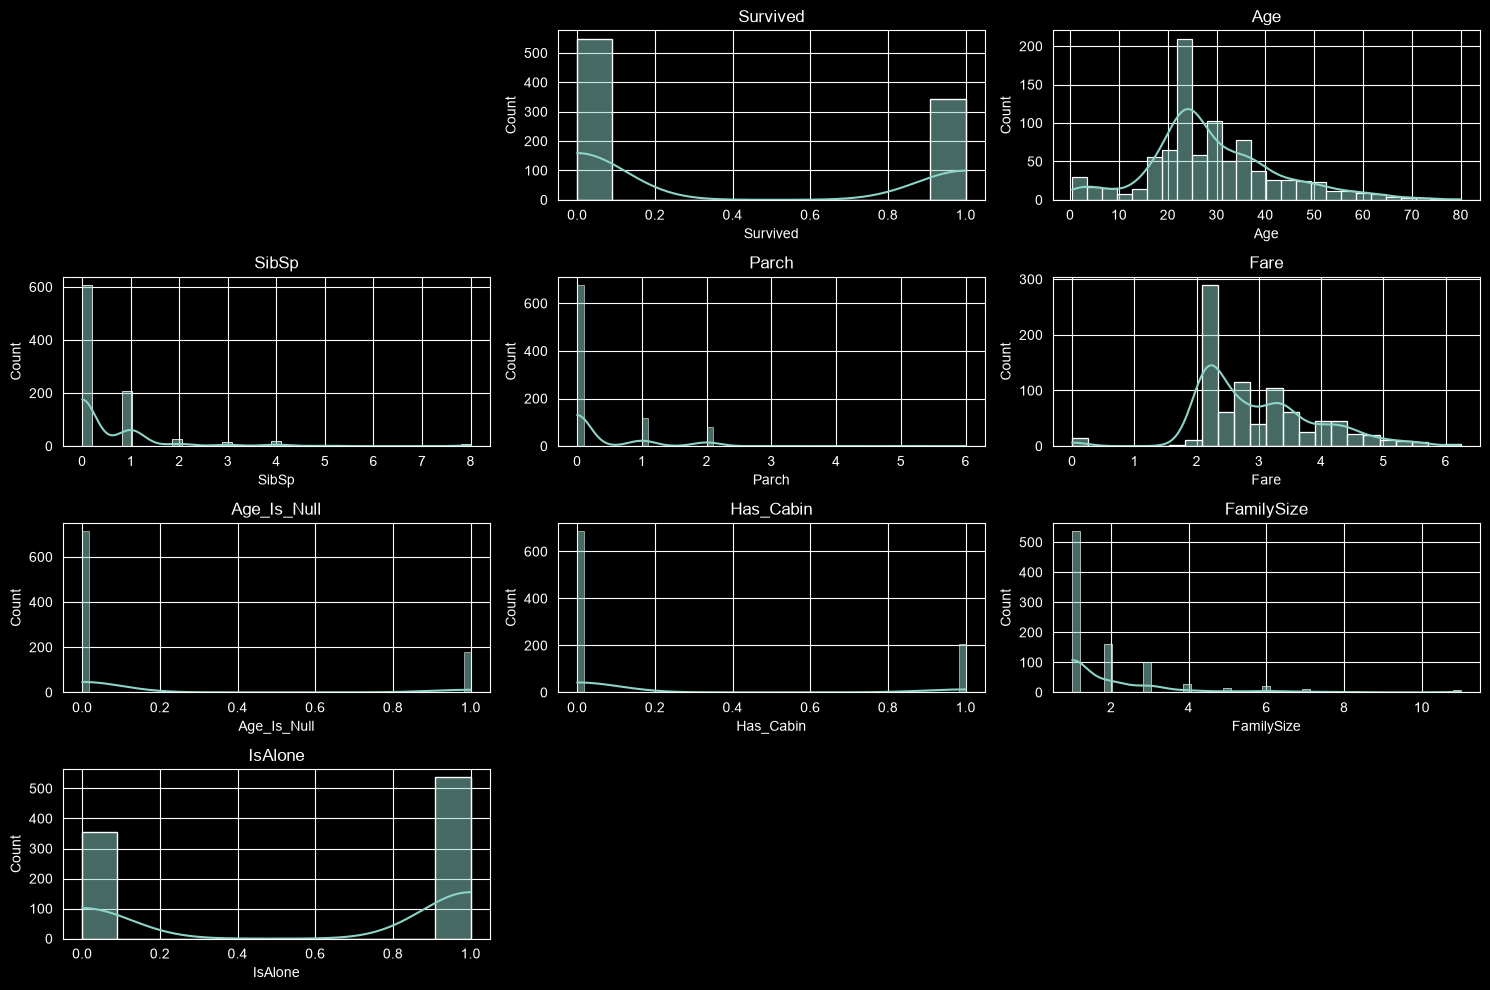

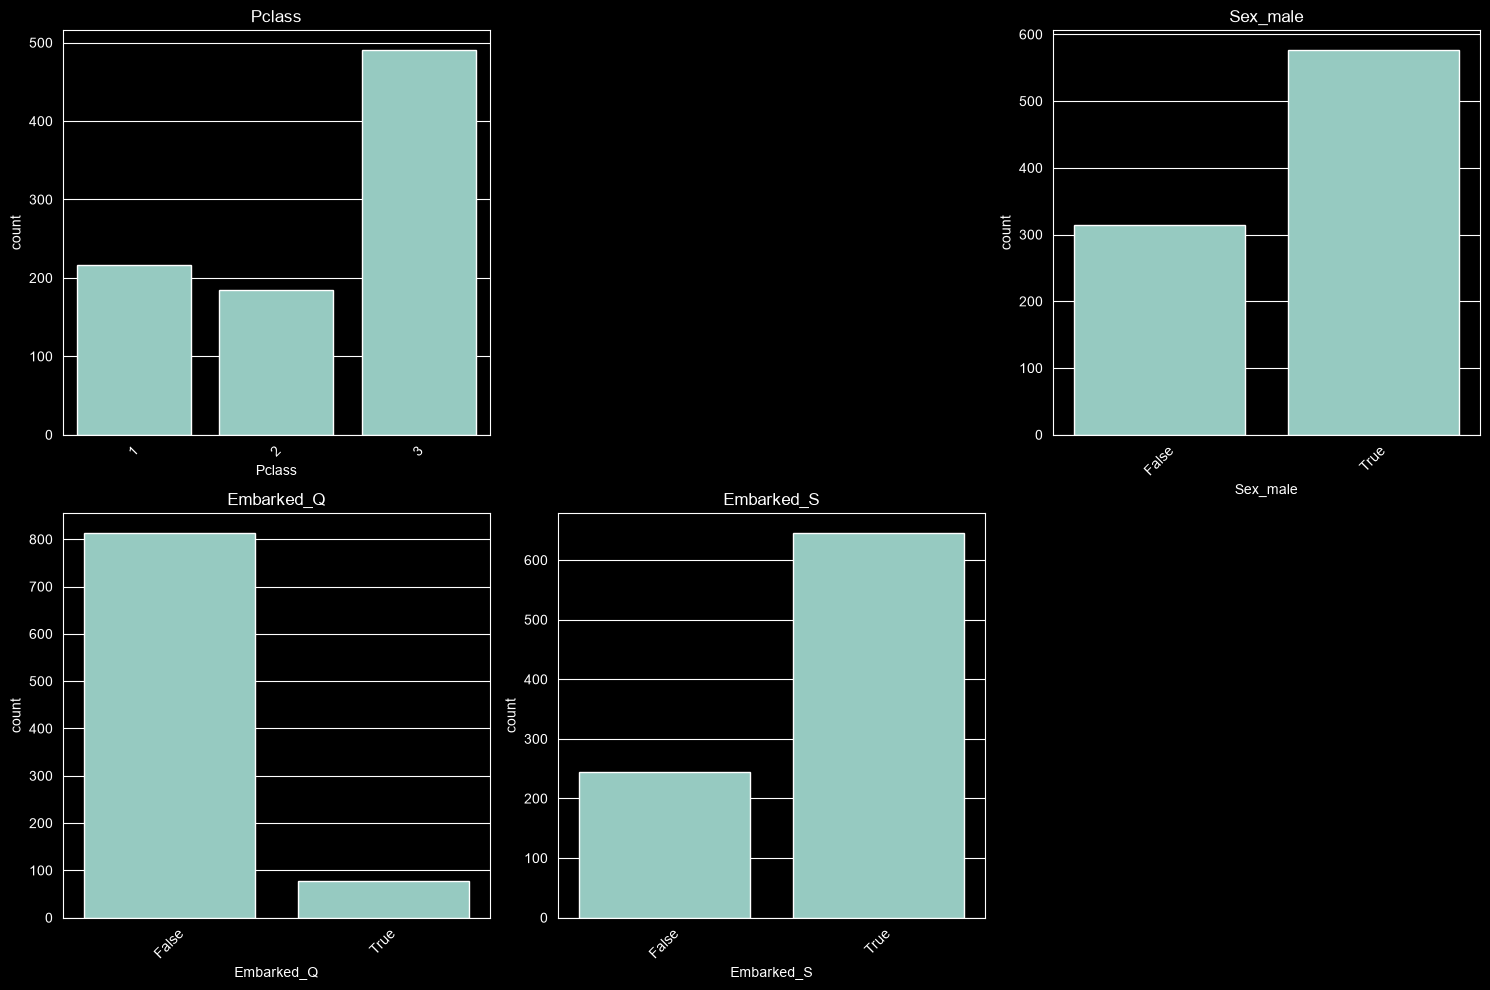

In [34]:
numerical_features = df.select_dtypes(include=['int64', 'float64']).columns
categorical_features = df.select_dtypes(
    include=['object', 'category', 'bool']
).columns

plt.figure(figsize=(15, 10))
for i, col in enumerate(numerical_features):
  if col == "PassengerId":
      continue
  plt.subplot((len(numerical_features) // 3) + 1, 3, i + 1)
  sns.histplot(df[col], kde=True)
  plt.title(col)
plt.tight_layout()
plt.show()

plt.figure(figsize=(15, 10))
for i, col in enumerate(categorical_features):
  if col == "Name":
      continue
  plt.subplot((len(categorical_features) // 3) + 1, 3, i + 1)
  sns.countplot(data=df, x=col)
  plt.title(col)
  plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Итого, у нас есть инсайты по выживаемости людей с пропуском возраста, пропуски возраста обработаны по классу билета, при помощи медианы, также есть новая фича, которая показывает была ли у человека каюта, она сильно вляет на выживаемость

Пол превращен из male/female в бинарный признак через OHE

Embarked - также превращен через OHE, пропуски заполнены модой

Есть новый признак, размер семьи, образованный из SIbSp и Parch, также есть признак, был ли человек 1 на борту

Колонка с номером билета дропнута

Fare прологорифмирован, чтобы получить распределение ближе к нормальному


В дальнейшем можно попробовать объединить людей в возрастные группы, Sibsp объединить в группу 3+/4+, parch объединить в группу 3+

посчитаны различные числовые статистики,

также Pclass преобразован в ординальный признак



In [35]:
from sklearn.linear_model import LogisticRegression #logistic regression
from sklearn import svm #support vector Machine
from sklearn.ensemble import RandomForestClassifier #Random Forest
from sklearn.neighbors import KNeighborsClassifier #KNN
from sklearn.naive_bayes import GaussianNB #Naive bayes
from sklearn.tree import DecisionTreeClassifier #Decision Tree
from sklearn.model_selection import train_test_split #training and testing data split
from sklearn import metrics #accuracy measure
from sklearn.metrics import confusion_matrix #for confusion matrix


In [41]:
df.drop('PassengerId', axis=1, inplace=True)
df.drop('Name', axis=1, inplace=True)


In [46]:
test_df = pd.read_csv(Config.TEST_DIR)

In [48]:
df.isnull().sum()

Survived       0
Pclass         0
Age            0
SibSp          0
Parch          0
Fare           0
Age_Is_Null    0
Has_Cabin      0
Sex_male       0
Embarked_Q     0
Embarked_S     0
FamilySize     0
IsAlone        0
dtype: int64

In [67]:
import importlib
import config

importlib.reload(config)
from config import Config

In [81]:
import importlib
import process_data_titanic

importlib.reload(process_data_titanic)
from process_data_titanic import process_data
train_df, age_medians, fare_median, embarked_mode, age_median = process_data(
    Config.TRAIN_DIR, is_train=True
)

test_df = process_data(
    Config.TEST_DIR,
    is_train=False,
    age_medians=age_medians,
    fare_median=fare_median,
    embarked_mode=embarked_mode,
    age_median=age_median
)

train_df.to_csv(Config.PROCESSED_DIR /  "train_processed.csv", index=False)
test_df.to_csv(Config.PROCESSED_DIR / "test_processed.csv", index=False)

In [80]:
train_df.columns

Index(['Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'Age_Is_Null',
       'Has_Cabin', 'Sex_male', 'Embarked_Q', 'Embarked_S', 'FamilySize',
       'IsAlone'],
      dtype='str')

In [82]:
from sklearn.model_selection import cross_val_score

train_df = pd.read_csv(Config.PROCESSED_DIR / "train_processed.csv")

X = train_df.drop(("Survived"), axis=1)
y = train_df["Survived"]

model = LogisticRegression(random_state=Config.RANDOM_STATE, max_iter=1000)

scores = cross_val_score(model, X, y, cv=5, scoring="accuracy")

print(f"Mean Accuracy: {scores.mean():.4f}")

Mean Accuracy: 0.8014


In [84]:
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from config import Config

train_df = pd.read_csv(Config.PROCESSED_DIR / "train_processed.csv")

X = train_df.drop("Survived", axis=1)
y = train_df["Survived"]

model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(random_state=Config.RANDOM_STATE, max_iter=1000, re))
])

scores = cross_val_score(model, X, y, cv=5, scoring="accuracy")

print(f"Mean Accuracy: {scores.mean():.4f}")

Mean Accuracy: 0.8025


In [85]:
from catboost import CatBoostClassifier

cat_model = CatBoostClassifier(random_seed=Config.RANDOM_STATE, verbose=0)

scores_cat = cross_val_score(cat_model, X, y, cv=5, scoring="accuracy")

print(f"CatBoost Mean Accuracy: {scores_cat.mean():.4f}")

CatBoost Mean Accuracy: 0.8238


In [87]:
import pandas as pd
from lightgbm import LGBMClassifier
from sklearn.model_selection import cross_val_score
from config import Config

train_df = pd.read_csv(Config.PROCESSED_DIR / "train_processed.csv")

X = train_df.drop("Survived", axis=1)
y = train_df["Survived"]

lgbm_model = LGBMClassifier(random_state=Config.RANDOM_STATE, verbose=-1)

scores_lgbm = cross_val_score(lgbm_model, X, y, cv=5, scoring="accuracy")

print(f"LightGBM Mean Accuracy: {scores_lgbm.mean():.4f}")

LightGBM Mean Accuracy: 0.8272


In [89]:
from sklearn.ensemble import GradientBoostingClassifier

grad_model = GradientBoostingClassifier(random_state=Config.RANDOM_STATE, verbose=0)

scores_gbc = cross_val_score(grad_model, X, y, cv=5, scoring="accuracy")
print(f"GradientBoost Mean Accuracy: {scores_gbc.mean():.4f}")

GradientBoost Mean Accuracy: 0.8238
